In [39]:
# Configs
import random
from pathlib import Path

import numpy as np
import torch

import time

random_state = 42
n_samples = 1000
noise = 0.2
test_size = 0.3
val_size = 0.5
batch_size = 32
input_dim = 2
hidden_dim = [16, 16]
output_dim = 2
lr = 0.1
num_epochs = 100

run_mode = "train"
model_path = Path("mlp_moons.pth")


def set_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_random_seed(random_state)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda:0


In [40]:
# 生成数据集
from sklearn.datasets import make_moons

X, Y = make_moons(
    n_samples=n_samples,
    noise=noise,
    random_state=random_state
)

X.shape, Y.shape

((1000, 2), (1000,))

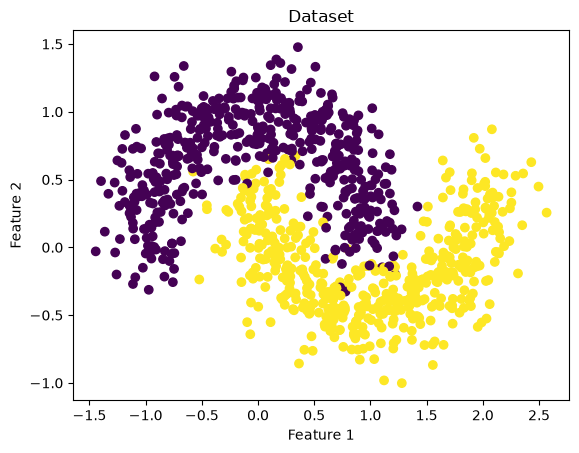

In [41]:
# 可视化
import matplotlib.pyplot as plt

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=Y
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset")
plt.show()

In [42]:
# 数据集划分：70:15:15
# 职责说明：训练集是训练某一个具体模型的数据，用于训练得到模型的参数；验证集用于同一模型或不同模型比较效果，可以测试选择不同的学习率，批量大小等超参数，或比较不同模型结构；测试集用于最终的模型效果测试，测试训练好的模型的实际效果
from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size=test_size,
    random_state=random_state,
    stratify=Y
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=val_size,
    random_state=random_state,
    stratify=Y_temp
)

(X_train.shape, X_val.shape, X_test.shape, Y_train.shape, Y_val.shape, Y_test.shape)

((700, 2), (150, 2), (150, 2), (700,), (150,), (150,))

In [43]:
# 格式处理;得到Dataset
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

Y_train = torch.tensor(Y_train, dtype=torch.long)
Y_val = torch.tensor(Y_val, dtype=torch.long)
Y_test = torch.tensor(Y_test, dtype=torch.long)

print(X_train.shape, X_train.dtype)
print(Y_train.shape, Y_train.dtype)

train_dataset = TensorDataset(X_train, Y_train)
val_dataset = TensorDataset(X_val, Y_val)
test_dataset = TensorDataset(X_test, Y_test)

torch.Size([700, 2]) torch.float32
torch.Size([700]) torch.int64


In [44]:
# 得到Dataloader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [45]:
# MLP搭建
import torch.nn as nn


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = list(hidden_dim)
        self.output_dim = output_dim

        self.network = nn.Sequential(
            nn.Linear(self.input_dim, self.hidden_dim[0]),
            nn.ReLU(),
            nn.Linear(self.hidden_dim[0], self.hidden_dim[1]),
            nn.ReLU(),
            nn.Linear(self.hidden_dim[1], self.output_dim),
        )

    def forward(self, x):
        return self.network(x)


def create_model(input_dim, hidden_dim, output_dim):
    return MLP(input_dim, hidden_dim, output_dim).to(device)


In [46]:
# 损失函数 CrossEntropyLoss
criterion = nn.CrossEntropyLoss()

In [47]:
# 训练一个 epoch，返回该轮的平均损失和准确率
def train_one_epoch(model, optimizer):
    model.train()
    train_total_loss = 0.0
    correct = 0
    total = 0

    for X_batch, Y_batch in train_loader:
        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)

        optimizer.zero_grad()
        output = model(X_batch)
        loss = criterion(output, Y_batch)
        loss.backward()
        optimizer.step()

        predictions = output.argmax(dim=1)
        correct += (predictions == Y_batch).sum().item()
        total += Y_batch.size(0)
        train_total_loss += loss.item() * Y_batch.size(0)

    return train_total_loss / total, correct / total


# eval模式
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)
            output = model(X_batch)
            loss = criterion(output, Y_batch)

            total_loss += loss.item() * Y_batch.size(0)
            correct += (output.argmax(dim=1) == Y_batch).sum().item()
            total += Y_batch.size(0)

    return total_loss / total, correct / total

In [48]:
# MLP训练
def train_model(model, optimizer):
    train_loss1, train_accuracy1 = [], []
    val_loss1, val_accuracy1 = [], []

    for epoch in range(num_epochs):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
            torch.cuda.reset_peak_memory_stats(device)

        train_start = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, optimizer)

        if device.type == "cuda":
            torch.cuda.synchronize(device)
            peak_vram_mb = torch.cuda.max_memory_allocated(device) / 1024**2
        else:
            peak_vram_mb = None

        train_seconds = time.perf_counter() - train_start

        val_start = time.perf_counter()
        val_loss, val_accuracy = evaluate(model, val_loader)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        val_seconds = time.perf_counter() - val_start

        train_loss1.append(train_loss)
        train_accuracy1.append(train_accuracy)
        val_loss1.append(val_loss)
        val_accuracy1.append(val_accuracy)

        samples_per_second = len(train_loader.dataset) / train_seconds
        memory_text = (
            f"{peak_vram_mb:.1f} MB" if peak_vram_mb is not None else "不适用（CPU）"
        )

        print(
            f"epoch:{epoch + 1}, "
            f"train_loss:{train_loss:.4f}, train_accuracy:{train_accuracy:.4f}, "
            f"val_loss:{val_loss:.4f}, val_accuracy:{val_accuracy:.4f}, "
            f"train_time:{train_seconds:.3f}s, "
            f"val_time:{val_seconds:.3f}s, "
            f"speed:{samples_per_second:.0f} samples/s, "
            f"peak_vram:{memory_text}"
        )

    print("训练结束")
    return train_loss1, train_accuracy1, val_loss1, val_accuracy1


In [49]:
# MLP保存与加载
def save_model(model, path):
    checkpoint = {
        "input_dim": model.input_dim,
        "hidden_dim": model.hidden_dim,
        "output_dim": model.output_dim,
        "model_state_dict": model.state_dict(),
    }
    torch.save(checkpoint, path)


def load_model(path):
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = create_model(
        checkpoint["input_dim"],
        checkpoint["hidden_dim"],
        checkpoint["output_dim"],
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model


In [50]:
# 绘制loss、accuracy 曲线及二维决策边界
def plot_training_results(model, train_loss, train_accuracy, val_loss, val_accuracy,
                          X_plot, Y_plot):
    epochs = np.arange(1, len(train_loss) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    axes[0].plot(epochs, train_loss, label="Train")
    axes[0].plot(epochs, val_loss, label="Validation")
    axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()

    axes[1].plot(epochs, train_accuracy, label="Train")
    axes[1].plot(epochs, val_accuracy, label="Validation")
    axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
    axes[1].legend()

    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200),
    )
    grid = np.column_stack((xx.ravel(), yy.ravel())).astype(np.float32)
    grid_tensor = torch.from_numpy(grid).to(device)

    was_training = model.training
    model.eval()
    with torch.no_grad():
        predicted = model(grid_tensor).argmax(dim=1).cpu().numpy().reshape(xx.shape)
    if was_training:
        model.train()

    axes[2].contourf(xx, yy, predicted, levels=[-0.5, 0.5, 1.5],
                     cmap="coolwarm", alpha=0.35)
    axes[2].scatter(X_plot[:, 0], X_plot[:, 1], c=Y_plot,
                    cmap="coolwarm", s=18, edgecolors="k", linewidths=0.2)
    axes[2].set(title="Decision boundary (train set)",
                xlabel="Feature 1", ylabel="Feature 2")

    fig.tight_layout()
    plt.show()

### 选择训练或加载

在最上面的配置单元格设置 `run_mode`：

- `"train"`：重新训练并验证，保存到 `model_path`，再从文件加载模型用于测试。
- `"load"`：跳过训练和验证，直接从 `model_path` 加载模型用于测试。首次运行前必须先生成该文件。

两种模式都需要先运行配置、数据准备、`MLP`、`evaluate` 及下面的函数定义单元格。

epoch:1, train_loss:0.6155, train_accuracy:0.7729, val_loss:0.5136, val_accuracy:0.8133, train_time:0.043s, val_time:0.004s, speed:16152 samples/s, peak_vram:64.0 MB
epoch:2, train_loss:0.4600, train_accuracy:0.7986, val_loss:0.3682, val_accuracy:0.8400, train_time:0.033s, val_time:0.004s, speed:21092 samples/s, peak_vram:64.0 MB
epoch:3, train_loss:0.3773, train_accuracy:0.8129, val_loss:0.3175, val_accuracy:0.8533, train_time:0.036s, val_time:0.004s, speed:19476 samples/s, peak_vram:64.0 MB
epoch:4, train_loss:0.3455, train_accuracy:0.8414, val_loss:0.2902, val_accuracy:0.8733, train_time:0.031s, val_time:0.004s, speed:22744 samples/s, peak_vram:64.0 MB
epoch:5, train_loss:0.3250, train_accuracy:0.8486, val_loss:0.2732, val_accuracy:0.8867, train_time:0.034s, val_time:0.006s, speed:20849 samples/s, peak_vram:64.0 MB
epoch:6, train_loss:0.3179, train_accuracy:0.8557, val_loss:0.2663, val_accuracy:0.8867, train_time:0.036s, val_time:0.003s, speed:19645 samples/s, peak_vram:64.0 MB
epoc

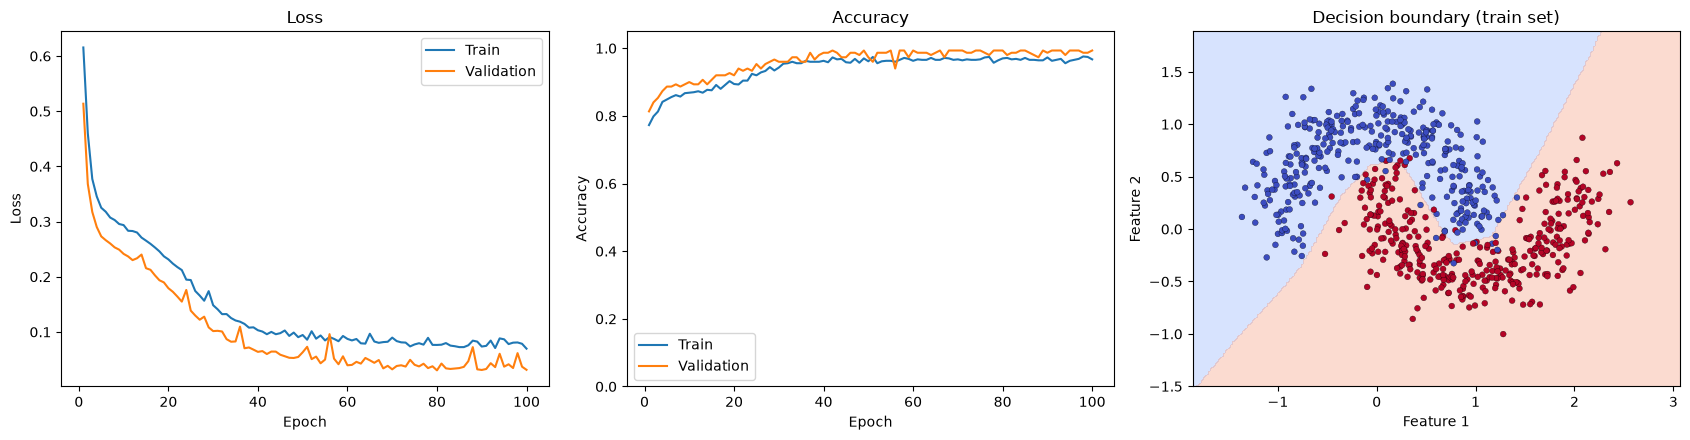

模型已保存到: D:\jotang\missions\ml_1\mlp_moons.pth
已加载模型


In [51]:
# 选择运行路径
if run_mode == "train":
    set_random_seed(random_state)
    model = create_model(input_dim, hidden_dim, output_dim)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    train_loss1, train_accuracy1, val_loss1, val_accuracy1 = train_model(model, optimizer)
    plot_training_results(
        model, train_loss1, train_accuracy1, val_loss1, val_accuracy1,
        X_train.numpy(), Y_train.numpy(),
    )
    save_model(model, model_path)
    print(f"模型已保存到: {model_path.resolve()}")
    model = load_model(model_path)
    print("已加载模型")
elif run_mode == "load":
    model = load_model(model_path)
    print(f"已加载模型: {model_path.resolve()}")

In [52]:
# MLP测试
def test_model(model, loader):
    return evaluate(model, loader)


test_loss, test_accuracy = test_model(model, test_loader)
print(f"test_loss:{test_loss:.4f}, test_accuracy:{test_accuracy:.4f}")


test_loss:0.0846, test_accuracy:0.9800


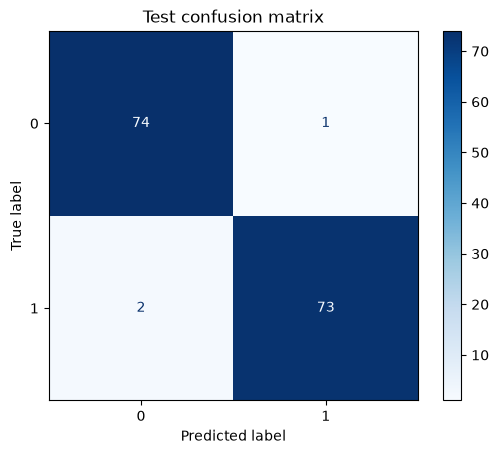

测试集错误样本数：3 / 150
测试集编号 50: 坐标=[ 0.746 -0.123], 真实=0, 预测=1, 预测类别的概率=0.534
测试集编号 94: 坐标=[-0.454  0.281], 真实=1, 预测=0, 预测类别的概率=0.770
测试集编号 134: 坐标=[-0.578  0.559], 真实=1, 预测=0, 预测类别的概率=0.999


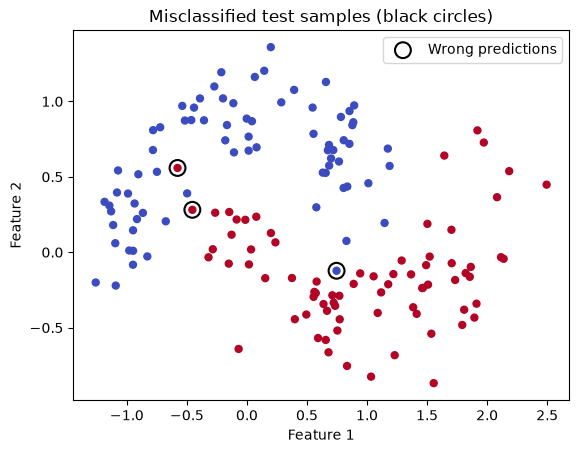

In [54]:
# 输出测试集上的混淆矩阵，输出错误样本信息
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def analyze_test_errors(model, X_test, Y_test, max_examples=5):
    model.eval()
    with torch.no_grad():
        logits = model(X_test.to(device))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

    X_np = X_test.cpu().numpy()
    y_true = Y_test.cpu().numpy()
    y_pred = probabilities.argmax(axis=1)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=[0, 1]
    ).plot(cmap="Blues", values_format="d")
    plt.title("Test confusion matrix")
    plt.show()

    wrong_indices = np.flatnonzero(y_pred != y_true)
    print(f"测试集错误样本数：{len(wrong_indices)} / {len(y_true)}")

    for i in wrong_indices[:max_examples]:
        print(
            f"测试集编号 {i}: 坐标={X_np[i].round(3)}, "
            f"真实={y_true[i]}, 预测={y_pred[i]}, "
            f"预测类别的概率={probabilities[i, y_pred[i]]:.3f}"
        )

    plt.scatter(X_np[:, 0], X_np[:, 1], c=y_true, cmap="coolwarm", s=25)
    if len(wrong_indices) > 0:
        plt.scatter(
            X_np[wrong_indices, 0], X_np[wrong_indices, 1],
            facecolors="none", edgecolors="black",
            s=130, linewidths=1.5, label="Wrong predictions"
        )
        plt.legend()
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Misclassified test samples (black circles)")
    plt.show()

    return cm, wrong_indices

cm, wrong_indices = analyze_test_errors(model, X_test, Y_test)